# Paris air quality forecasting

Goal: forecast the next 504 hours (3 weeks) of NO2, CO, O3, PM10 and PM25 in Paris. I compare simple baselines, Chronos-2 in zero-shot and a small LSTM, all on the same validation window.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    !pip install -q chronos-forecasting holidays
    DATA_DIR = Path("data/raw")
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if not (DATA_DIR / "train.csv").exists():
        from google.colab import files
        for name, content in files.upload().items():  # pick the 3 CSVs
            (DATA_DIR / name).write_bytes(content)
else:
    DATA_DIR = Path("../data/raw")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 3.2 MB/s eta 0:00:00


Saving train.csv to train.csv
Saving test.csv to test.csv
Saving sample_submission.csv to sample_submission.csv


## 1. Loading the data

In [2]:
def load(path):
    return pd.read_csv(path, index_col="id", parse_dates=["id"], date_format="%Y-%m-%d %H")

train = load(DATA_DIR / "train.csv")
test = load(DATA_DIR / "test.csv")

print(train.shape, test.shape)
print(train.dtypes)
train.head()

(40991, 5) (504, 0)
valeur_NO2     float64
valeur_CO      float64
valeur_O3      float64
valeur_PM10    float64
valeur_PM25    float64
dtype: object


,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
id,,,,,
2020-01-01 00:00:00,42.9,0.718,15.7,73.1,64.4
2020-01-01 01:00:00,33.6,0.587,10.1,74.8,66.0
2020-01-01 02:00:00,29.3,NaN,5.1,51.0,44.9
2020-01-01 03:00:00,30.5,0.246,7.2,27.7,25.1
2020-01-01 04:00:00,29.3,0.204,8.3,15.3,13.6


In [3]:
print("train:", train.index.min(), train.index.max())
print("test: ", test.index.min(), test.index.max())

train: 2020-01-01 00:00:00 2024-09-03 22:00:00
test:  2024-09-03 23:00:00 2024-09-24 22:00:00


In [4]:
POLLUTANTS = ["valeur_NO2", "valeur_CO", "valeur_O3", "valeur_PM10", "valeur_PM25"]

assert list(train.columns) == POLLUTANTS

In [5]:
# sorted
print("sorted:", train.index.is_monotonic_increasing)

# duplicates
print("duplicated timestamps:", train.index.duplicated().sum())

# missing hours
full_range = pd.date_range(train.index.min(), train.index.max(), freq="h")
missing_hours = full_range.difference(train.index)
print("expected hours:", len(full_range), ", rows:", len(train))
print("missing hours:", len(missing_hours))

# train and test connect
print("gap train, test:", test.index[0] - train.index[-1])
print("test rows:", len(test))

sorted: True
duplicated timestamps: 0
expected hours: 40991 , rows: 40991
missing hours: 0
gap train, test: 0 days 01:00:00
test rows: 504


The data is hourly, sorted, with no duplicated or missing timestamps. The test period starts exactly one hour after the end of train and lasts 504 hours.

Each value depends on the ones before it, so the order of the rows matters. This is a forecasting problem, and I can't shuffle the rows or split them randomly: the model would be trained on hours that come after the ones it is tested on.

## 2. Data quality

In [6]:
train[POLLUTANTS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
valeur_NO2,37694.0,21.83,14.66,1.10,11.30,17.60,28.20,131.00
valeur_CO,28462.0,0.20,0.10,0.04,0.14,0.18,0.23,4.31
valeur_O3,40298.0,50.57,26.49,-1.90,33.00,50.70,66.60,193.10
valeur_PM10,33824.0,18.22,11.28,0.50,10.70,15.60,22.90,128.50
valeur_PM25,39200.0,11.05,8.15,0.00,5.80,8.70,13.60,111.10


The pollutants are on very different scales. CO is around 0.2 while O3 is around 50, so an average MAE over the five mostly reflects O3.

In [7]:
missing= pd.DataFrame({"n_missing":train.isna().sum(),"pct_missing":(train.isna().mean()*100).round(2)})
missing

,n_missing,pct_missing
valeur_NO2,3297,8.04
valeur_CO,12529,30.57
valeur_O3,693,1.69
valeur_PM10,7167,17.48
valeur_PM25,1791,4.37


In [8]:
# share of missing values per year in pct
missing_per_year =(train.isna().groupby(train.index.year).mean() * 100).round(1)
print(missing_per_year)
# longest run of consecutive missing hours per pollutant
for col in POLLUTANTS:
    na = train[col].isna()
    runs = na.groupby((~na).cumsum()).sum()
    print(col, ", longest gap:", runs.max(), "h, gaps over 24h:", (runs > 24).sum())


      valeur_NO2  valeur_CO  valeur_O3  valeur_PM10  valeur_PM25
id                                                              
2020         9.1        6.9        5.2         15.3         15.6
2021        20.6       98.8        0.6         10.3          2.4
2022         1.2       33.8        0.6         23.5          0.9
2023         0.4        2.7        0.8         17.9          0.8
2024         9.2        1.2        1.1         21.8          1.1
valeur_NO2 , longest gap: 1500 h, gaps over 24h: 9
valeur_CO , longest gap: 10949 h, gaps over 24h: 9
valeur_O3 , longest gap: 131 h, gaps over 24h: 6
valeur_PM10 , longest gap: 90 h, gaps over 24h: 28
valeur_PM25 , longest gap: 493 h, gaps over 24h: 10


CO is the worst: 30% missing, and almost all of 2021 is gone. PM10 has many short gaps every year. NO2 has one long outage in 2021. O3 and PM25 are nearly complete.

I don't interpolate. Interpolation uses the value after the gap, so near the end of train it would pull in values from the validation or test period. When a model needs complete inputs I only fill forward from past values.

negative values: valeur_NO2      0
valeur_CO       0
valeur_O3      10
valeur_PM10     0
valeur_PM25     0
dtype: int64


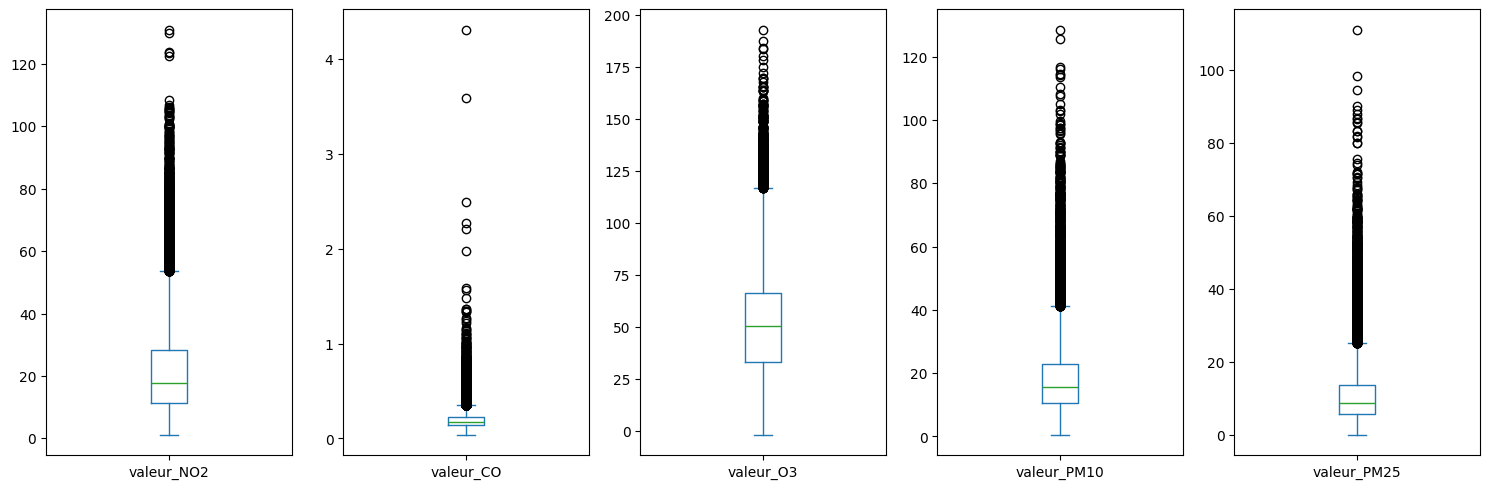

In [9]:
print("negative values:", (train < 0).sum())
train.quantile([0.5, 0.99, 0.999, 1.0]).T

train.plot(kind="box", subplots=True, layout=(1, 5),
           figsize=(15, 5), sharey=False)
plt.tight_layout()

In [10]:
train.quantile([0.5, 0.99, 0.999, 1.0]).T

,0.500,0.990,0.999,1.000
valeur_NO2,17.600,71.40000,97.361400,131.000
valeur_CO,0.177,0.58339,1.054929,4.309
valeur_O3,50.700,123.20300,153.770300,193.100
valeur_PM10,15.600,59.17700,89.717700,128.500
valeur_PM25,8.700,41.10000,64.380100,111.100


O3 has 10 slightly negative values, which is sensor noise around zero, so I leave them. CO has one big spike at 4.3, far above the rest. PM10 and PM25 reach their maximum at the same hour in January 2022, so that one looks like a real pollution episode.

## 3. What the series look like

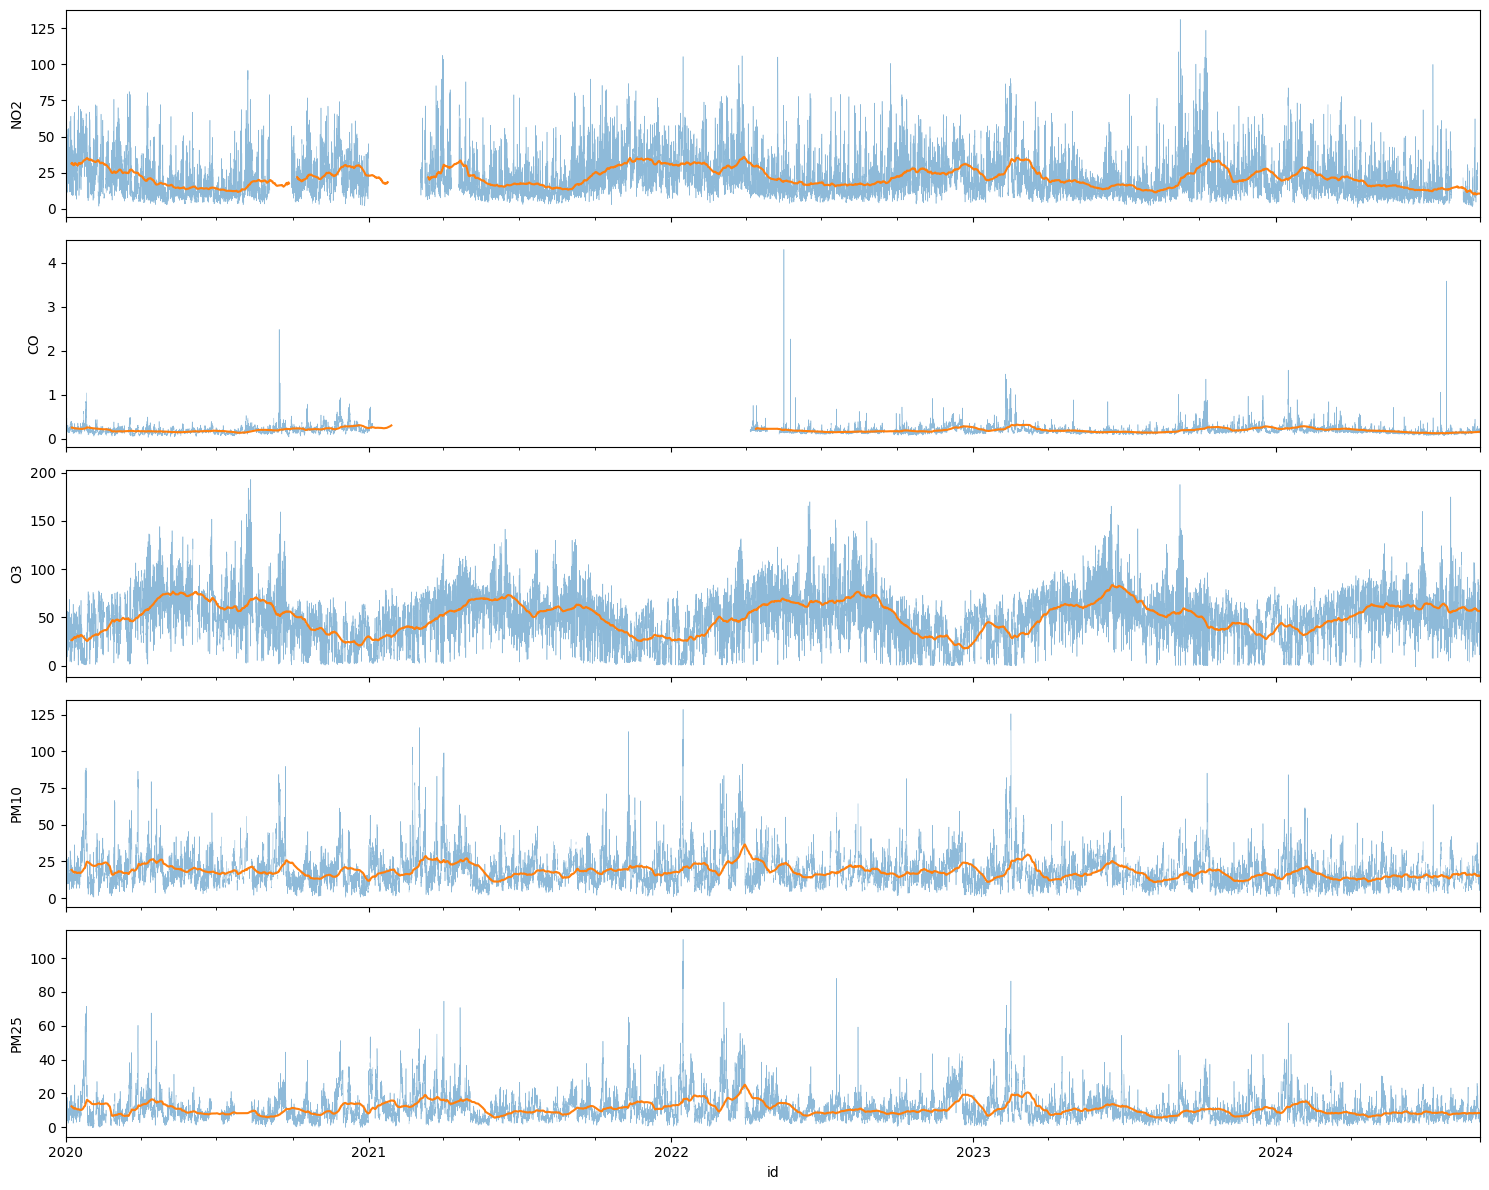

In [11]:
fig, axes = plt.subplots(5, 1, figsize=(15, 12), sharex=True)
for ax, col in zip(axes, POLLUTANTS):
    train[col].plot(ax=ax, lw=0.4, alpha=0.5)
    train[col].rolling(24 * 30, min_periods=24 * 7).mean().plot(ax=ax, lw=1.5)
    ax.set_ylabel(col.replace("valeur_", ""))

plt.tight_layout()

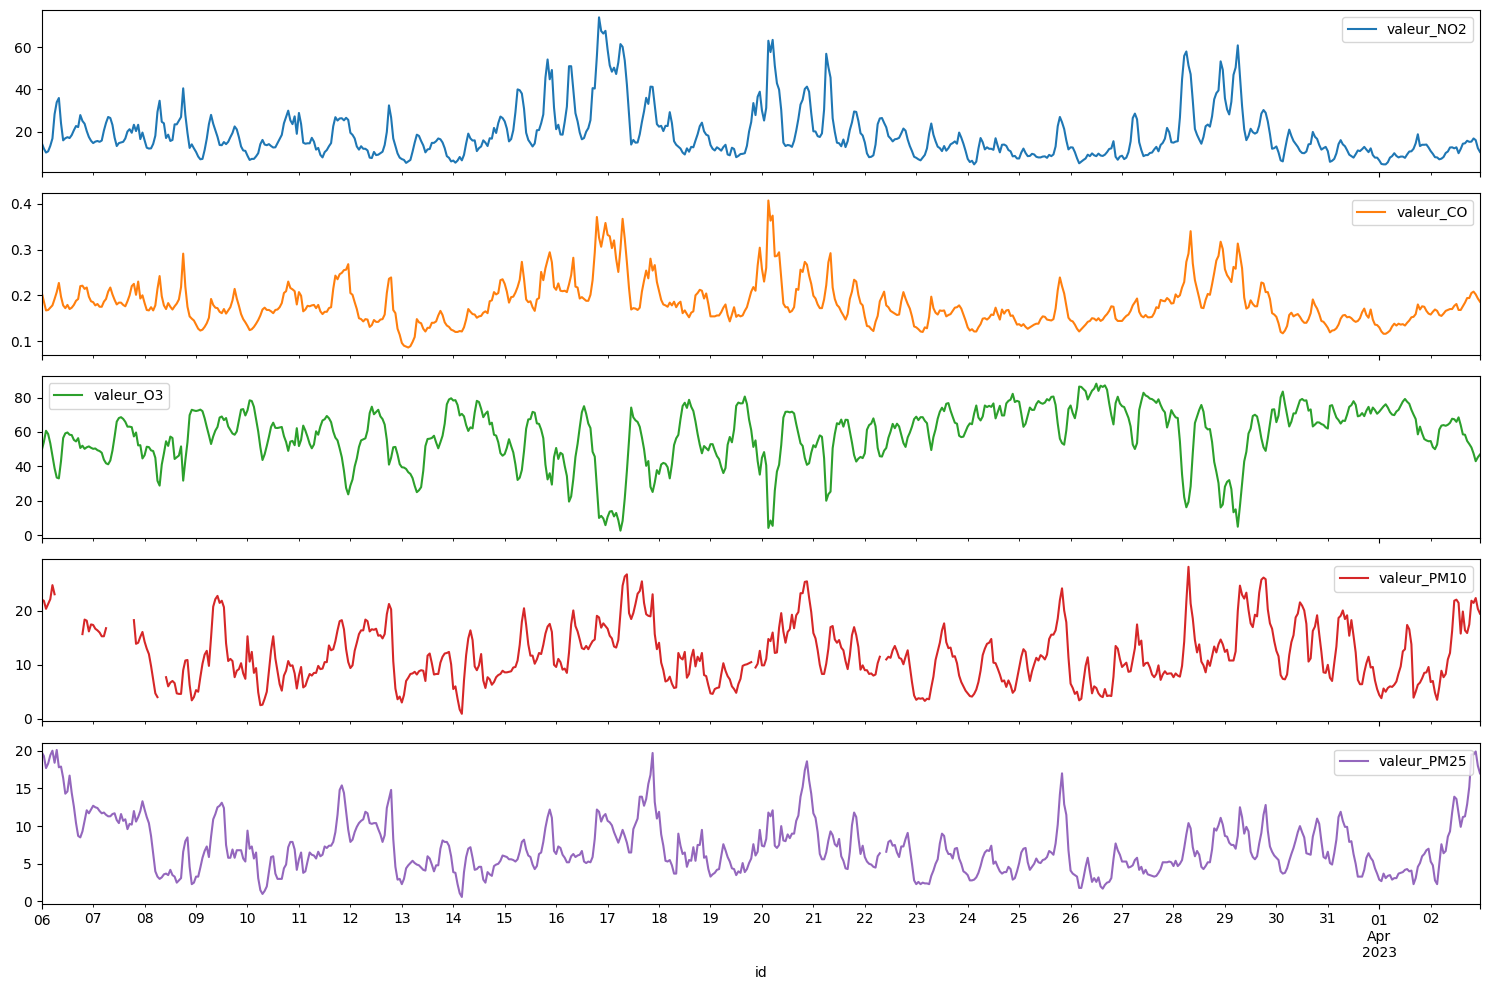

In [12]:
train.loc["2023-03-06":"2023-04-02", POLLUTANTS].plot(subplots=True, figsize=(15, 10))
plt.tight_layout()

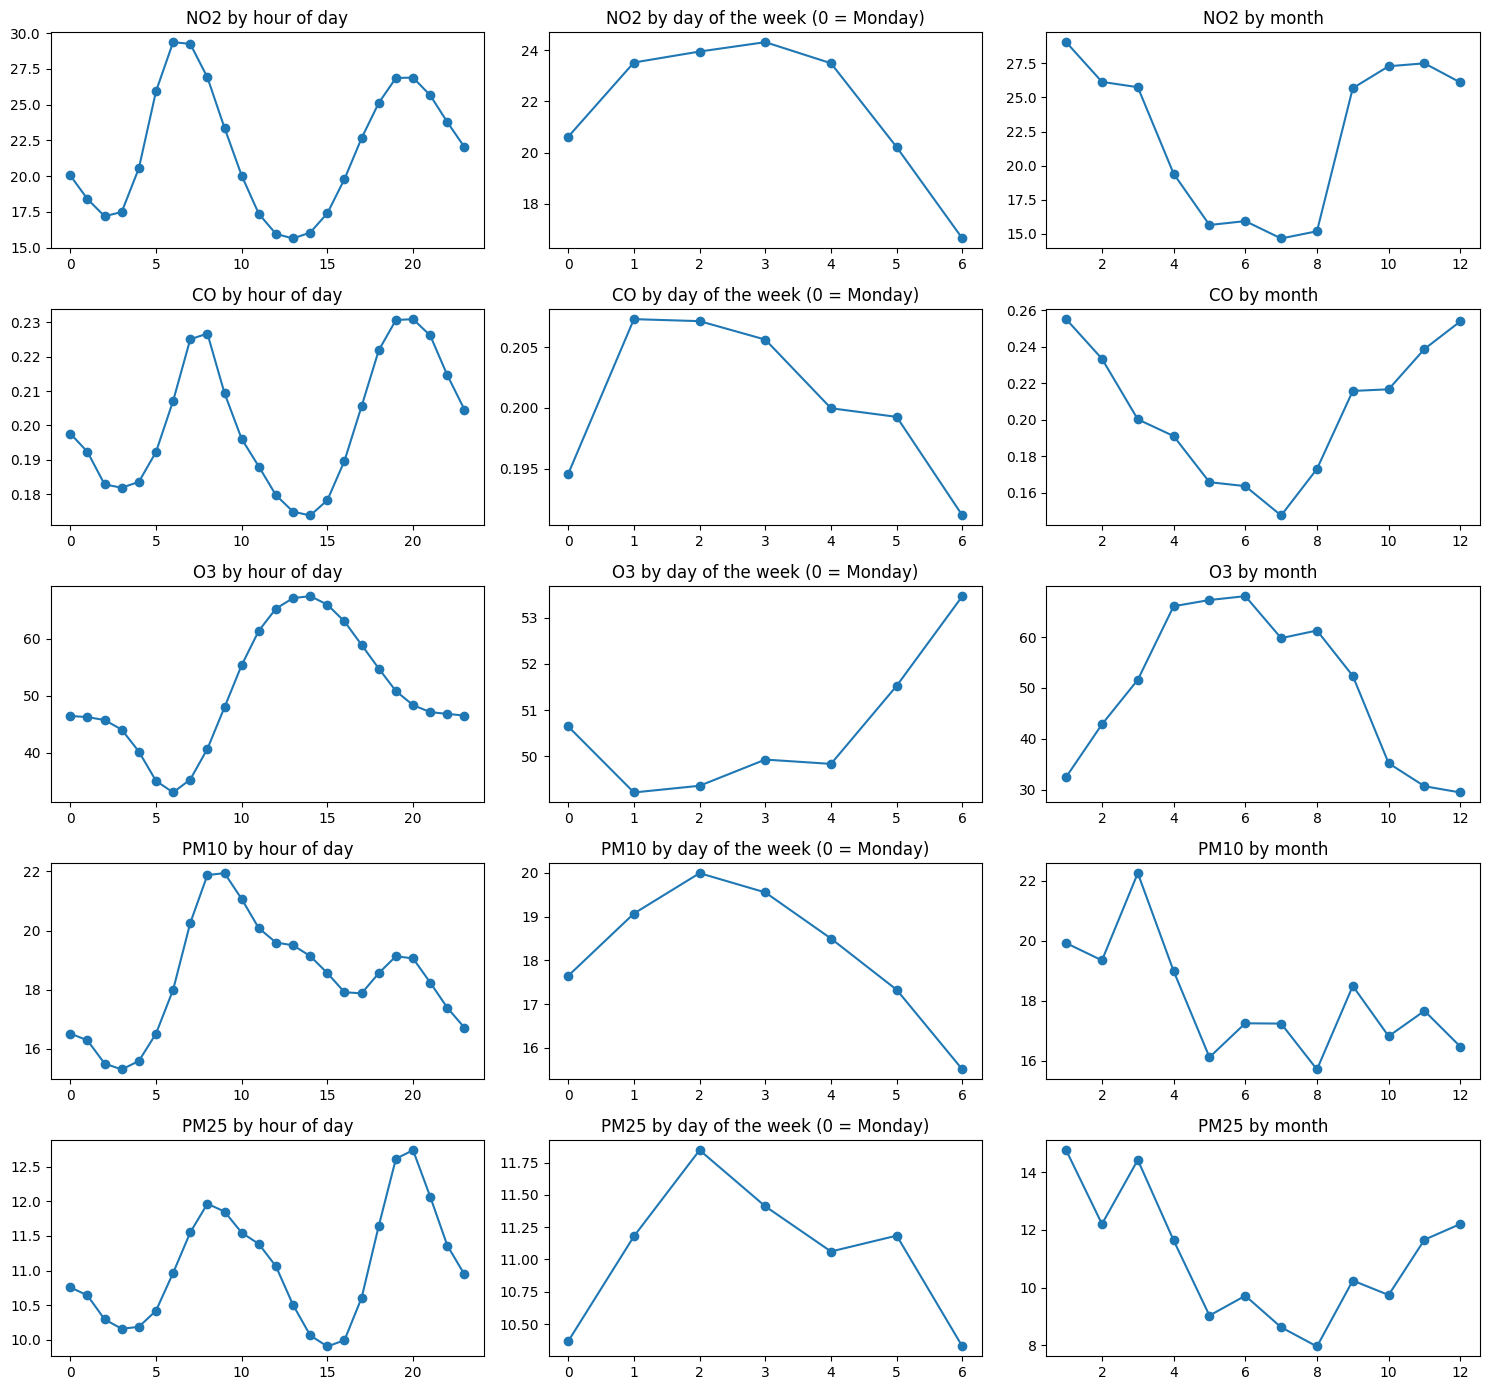

In [13]:
groups = {
    "hour of day": train.index.hour,
    "day of the week (0 = Monday)": train.index.dayofweek,
    "month": train.index.month,
}
fig, axes = plt.subplots(len(POLLUTANTS), 3, figsize=(15, 14))
for i, col in enumerate(POLLUTANTS):
    for j, (name, key) in enumerate(groups.items()):
        train[col].groupby(key).mean().plot(ax=axes[i, j], marker="o")
        axes[i, j].set_title(f"{col.replace('valeur_', '')} by {name}")
        axes[i, j].set_xlabel("")

plt.tight_layout()

NO2 has two peaks a day, at the morning and evening rush hours, and it is lower on weekends, lowest on Sunday. O3 does the opposite: low in the early morning, high in the afternoon, and much higher in summer than in winter. PM10 and PM25 have a weaker daily shape.

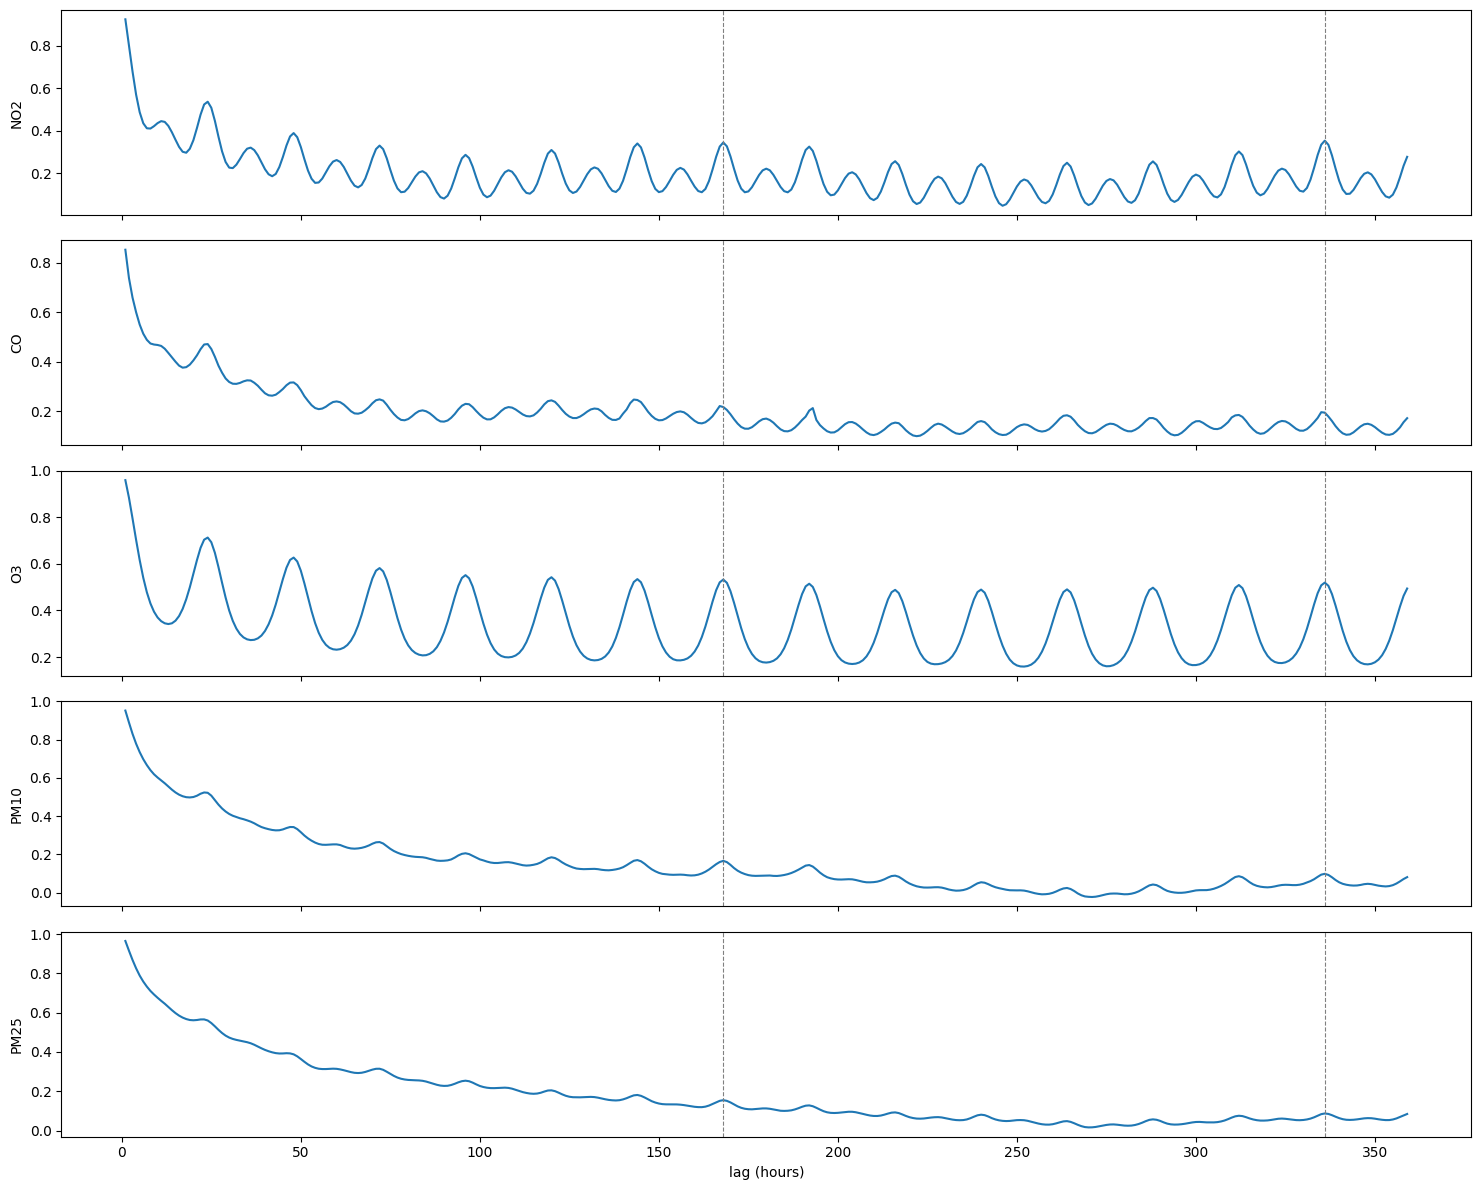

In [14]:
lags = range(1, 24 * 15)
fig, axes = plt.subplots(5, 1, figsize=(15, 12), sharex=True)
for ax, col in zip(axes, POLLUTANTS):
    ax.plot(lags, [train[col].autocorr(lag) for lag in lags])
    for week in (168, 336):
        ax.axvline(week, color="grey", ls="--", lw=0.8)
    ax.set_ylabel(col.replace("valeur_", ""))
axes[-1].set_xlabel("lag (hours)")
plt.tight_layout()

All five have bumps every 24 hours. At 168 hours (one week) the correlation is still clear for O3 and NO2 but weak for PM10 and PM25.

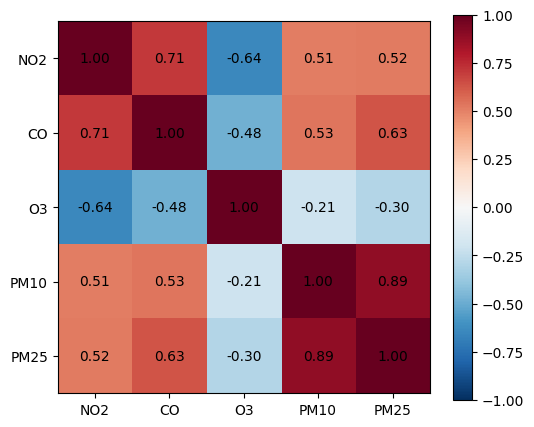

In [15]:
corr = train[POLLUTANTS].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
labels = [c.replace("valeur_", "") for c in POLLUTANTS]
ax.set_xticks(range(5), labels)
ax.set_yticks(range(5), labels)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)

PM10 and PM25 move together (0.89). NO2 and CO are linked (0.71), both are related to traffic. O3 goes against NO2 (-0.64).

## 4. Validation split

I keep the last 504 hours of train as validation, the same length as the test period. Everything before is used to fit, and the models never see anything after the split.

In [16]:
HORIZON = 504

train_fit = train.iloc[:-HORIZON]
valid = train.iloc[-HORIZON:]

assert train_fit.index.max() < valid.index.min()
print("fit: ", train_fit.index.min(), "->", train_fit.index.max())
print("valid: ", valid.index.min(), "->", valid.index.max(), ",", len(valid), "hours")
print("observed values in valid:", valid.count())

fit:  2020-01-01 00:00:00 -> 2024-08-13 22:00:00
valid:  2024-08-13 23:00:00 -> 2024-09-03 22:00:00 , 504 hours
observed values in valid: valeur_NO2     394
valeur_CO      498
valeur_O3      504
valeur_PM10    299
valeur_PM25    491
dtype: int64


NO2 and PM10 have many missing hours in this window (394 and 299 observed out of 504), so their MAE is computed on fewer points.

## 5. Baselines

Persistence repeats the last observed value. Seasonal naive repeats the last observed week (168 hours), which keeps both the daily cycle and the weekday/weekend difference. I also try a 24 hour lag to compare.

In [17]:
def persistence(history, index):
    last = history.ffill().iloc[-1]
    return pd.DataFrame([last.to_numpy()] * len(index), index=index, columns=history.columns)

In [18]:
def seasonal_naive(history, index, season=168):
    # position of each row whitin the season, counted so for forecast starts at phrase 0
    phase = (np.arange(len(history)) - len(history)) % season
    last_season = history.groupby(phase).last() # last non-missing val per phase
    steps = np.arange(len(index)) % season
    return pd.DataFrame(last_season.to_numpy()[steps], index=index, columns=history.columns)

In [19]:
def mae_table(y_true, preds):
    table = pd.DataFrame({name: (y_true - p).abs().mean() for name, p in preds.items()}).T
    table["average"] = table.mean(axis=1)
    return table.round(3)

preds = {
    "persistence": persistence(train_fit, valid.index),
    "seasonal_naive_24": seasonal_naive(train_fit, valid.index, season=24),
    "seasonal_naive_168": seasonal_naive(train_fit, valid.index, season=168),
 }
for p in preds.values():
    assert p.notna().all().all()

mae_table(valid, preds)

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,average
persistence,7.429,0.046,16.160,5.622,4.237,6.699
seasonal_naive_24,10.374,0.045,14.254,6.676,4.210,7.112
seasonal_naive_168,9.469,0.044,17.303,6.439,3.555,7.362


Persistence has the best average here, which I did not expect. But the winner changes with the pollutant: persistence for NO2 and PM10, the 24h lag for O3, the 168h lag for CO and PM25. This is why I look at the MAE per pollutant and not only the average.

NO2 has no observed value in the two weeks before the split, so both baselines work from older NO2 data.

## 6. Chronos-2 zero-shot

Chronos-2 is a pretrained time series model. I use it as it is, without training it on this data: it only receives the history before the validation period and predicts the 504 hours. I keep the median (quantile 0.5) as the forecast since the metric is MAE.

Settings: amazon/chronos-2, chronos-forecasting 2.3.2, Tesla T4 on Colab, default context length (8192 hours), no fine-tuning.

In [20]:
import torch
import chronos
from chronos import Chronos2Pipeline

MODEL_NAME = "amazon/chronos-2"
device = "cuda" if torch.cuda.is_available() else "cpu"
pipeline = Chronos2Pipeline.from_pretrained(MODEL_NAME, device_map=device)

print("model:", MODEL_NAME)
print("chronos-forecasting:", chronos.__version__, "| torch:", torch.__version__)
print("hardware:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

model: amazon/chronos-2
chronos-forecasting: 2.3.2 | torch: 2.11.0+cu130
hardware: Tesla T4


Joint: the five pollutants are given together as one multivariate series. Independent: each pollutant is forecast alone.

In [21]:
QUANTILES = [0.1, 0.5, 0.9]

def chronos_joint(history, horizon):
    context = history.reset_index().rename(columns={"id": "timestamp"})
    context["item_id"] = "paris"
    out = pipeline.predict_df(
        context,
        target=list(history.columns),
        prediction_length=horizon,
        quantile_levels=QUANTILES,
    )
    return out.pivot(index="timestamp", columns="target_name", values="0.5")[list(history.columns)]


In [22]:
def chronos_independent(history, horizon):
    context = (
        history.reset_index()
        .rename(columns={"id": "timestamp"})
        .melt(id_vars="timestamp", var_name="item_id", value_name="target")
    )
    out = pipeline.predict_df(
        context,
        target="target",
        prediction_length=horizon,
        quantile_levels=QUANTILES,
    )
    return out.pivot(index="timestamp", columns="item_id", values="0.5")[list(history.columns)]


In [23]:
preds["chronos2_joint"] = chronos_joint(train_fit, HORIZON)
preds["chronos2_independent"] = chronos_independent(train_fit, HORIZON)

for name in ("chronos2_joint", "chronos2_independent"):
    assert preds[name].index.equals(valid.index)
    assert preds[name].notna().all().all()

mae_table(valid, preds)

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,average
persistence,7.429,0.046,16.160,5.622,4.237,6.699
seasonal_naive_24,10.374,0.045,14.254,6.676,4.210,7.112
seasonal_naive_168,9.469,0.044,17.303,6.439,3.555,7.362
chronos2_joint,6.348,0.037,12.790,5.292,3.374,5.568
chronos2_independent,7.714,0.048,12.916,5.418,3.260,5.871


Both versions beat the baselines on average. Joint is better than independent mostly thanks to NO2 (6.35 vs 7.71) and CO, probably because NO2 has no recent values and the other pollutants help. Independent is slightly better on PM25, and persistence still beats independent Chronos on NO2.

## 7. LSTM

A small LSTM trained only on this dataset. It reads the last two weeks (336 hours) and outputs the 504 hours for the five pollutants in one go. Inputs are the scaled pollutants, a flag telling if each value was observed, and calendar features (hour, weekday, day of year).

Scaling uses the fit period only, gaps are filled forward from the past, and the loss is the absolute error on observed targets only.

In [24]:
from torch import nn
from torch.utils.data import Dataset, DataLoader

LOOKBACK = 336
EPOCHS = 15
SEED = 0

# scaling stats from the fit period only
mu, sigma = train_fit.mean(), train_fit.std()

In [25]:
def make_features(df):
    scaled = (df - mu) / sigma
    values = scaled.ffill().fillna(0.0)  # past values only
    observed = df.notna().astype("float32").add_suffix("_observed")
    idx = df.index
    calendar = pd.DataFrame({
        "hour_sin": np.sin(2 * np.pi * idx.hour / 24),
        "hour_cos": np.cos(2 * np.pi * idx.hour / 24),
        "dow_sin": np.sin(2 * np.pi * idx.dayofweek / 7),
        "dow_cos": np.cos(2 * np.pi * idx.dayofweek / 7),
        "doy_sin": np.sin(2 * np.pi * idx.dayofyear / 365.25),
        "doy_cos": np.cos(2 * np.pi * idx.dayofyear / 365.25),
    }, index=idx)
    X = pd.concat([values, observed, calendar], axis=1).to_numpy(dtype="float32")
    Y = scaled.to_numpy(dtype="float32")  # targets keep their NaN
    return X, Y


class WindowDataset(Dataset):
    # one sample = LOOKBACK hours of input and the HORIZON hours that follow
    def __init__(self, X, Y, lookback, horizon, stride=6):
        self.X, self.Y, self.lookback, self.horizon = X, Y, lookback, horizon
        self.starts = np.arange(0, len(X) - lookback - horizon + 1, stride)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        m = s + self.lookback
        return torch.from_numpy(self.X[s:m]), torch.from_numpy(self.Y[m:m + self.horizon])

In [26]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features, n_targets, horizon, hidden=64):
        super().__init__()
        self.n_targets, self.horizon = n_targets, horizon
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.head = nn.Linear(hidden, horizon * n_targets)

    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.head(h[-1]).view(-1, self.horizon, self.n_targets)


def masked_l1(pred, target):
    # absolute error, only where the target was observed
    mask = ~torch.isnan(target)
    return (pred - torch.nan_to_num(target)).abs()[mask].mean()


def fit(model, loader, epochs=EPOCHS, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = masked_l1(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item()
        print(f"epoch {epoch + 1:2d}, train loss {total / len(loader):.4f}")
    return model


def forecast(model, history, index):
    X, _ = make_features(history)
    x = torch.from_numpy(X[-LOOKBACK:]).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        out = model(x)[0].cpu().numpy()
    return pd.DataFrame(out, index=index, columns=POLLUTANTS) * sigma + mu

In [27]:
torch.manual_seed(SEED)
np.random.seed(SEED)

X, Y = make_features(train_fit)
loader = DataLoader(WindowDataset(X, Y, LOOKBACK, HORIZON), batch_size=64, shuffle=True)

lstm = fit(LSTMForecaster(X.shape[1], len(POLLUTANTS), HORIZON), loader)
preds["lstm"] = forecast(lstm, train_fit, valid.index)

mae_table(valid, preds)

epoch  1, train loss 0.6567
epoch  2, train loss 0.6145
epoch  3, train loss 0.5953
epoch  4, train loss 0.5834
epoch  5, train loss 0.5777
epoch  6, train loss 0.5734
epoch  7, train loss 0.5716
epoch  8, train loss 0.5679
epoch  9, train loss 0.5680
epoch 10, train loss 0.5654
epoch 11, train loss 0.5597
epoch 12, train loss 0.5576
epoch 13, train loss 0.5564
epoch 14, train loss 0.5557
epoch 15, train loss 0.5532


,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,average
persistence,7.429,0.046,16.160,5.622,4.237,6.699
seasonal_naive_24,10.374,0.045,14.254,6.676,4.210,7.112
seasonal_naive_168,9.469,0.044,17.303,6.439,3.555,7.362
chronos2_joint,6.348,0.037,12.790,5.292,3.374,5.568
chronos2_independent,7.714,0.048,12.916,5.418,3.260,5.871
lstm,6.964,0.031,14.506,5.527,3.555,6.117


The LSTM beats the baselines on average (6.12 against 6.70 for persistence) but stays behind both Chronos-2 versions. It is the best model on CO. It was trained once with one seed, so the numbers would move a bit with another run.

## 8. Results

In [28]:
results = mae_table(valid, preds).sort_values("average")
results

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,average
chronos2_joint,6.348,0.037,12.790,5.292,3.374,5.568
chronos2_independent,7.714,0.048,12.916,5.418,3.260,5.871
lstm,6.964,0.031,14.506,5.527,3.555,6.117
persistence,7.429,0.046,16.160,5.622,4.237,6.699
seasonal_naive_24,10.374,0.045,14.254,6.676,4.210,7.112
seasonal_naive_168,9.469,0.044,17.303,6.439,3.555,7.362


In [29]:
# best model for each pollutant
results.idxmin()

,0
valeur_NO2,chronos2_joint
valeur_CO,lstm
valeur_O3,chronos2_joint
valeur_PM10,chronos2_joint
valeur_PM25,chronos2_independent
average,chronos2_joint


Chronos-2 joint is the best on average, and the best on NO2, O3 and PM10. It is not the best everywhere: the LSTM wins on CO and independent Chronos-2 on PM25. The average hides this because it is dominated by O3, which has the largest values.

Seasonal naive with a 168h lag is last on average even though it is the best baseline on CO and PM25.

Does the error change along the horizon? MAE for each of the three weeks.

In [30]:
week = np.arange(HORIZON) // 168 + 1
by_week = pd.concat(
    {name: (valid - p).abs().groupby(week).mean() for name, p in preds.items()},
    names=["model", "week"],
)
by_week["average"] = by_week.mean(axis=1)
by_week["average"].unstack("week").round(3)

week,1,2,3
model,,,
persistence,6.335,6.969,6.808
seasonal_naive_24,6.912,7.268,7.081
seasonal_naive_168,6.807,7.230,7.941
chronos2_joint,4.902,5.424,6.408
chronos2_independent,5.371,5.592,6.548
lstm,5.958,6.003,6.515


In [31]:
# same thing per pollutant
by_week[POLLUTANTS].unstack("week").round(2)

valeur_NO2              valeur_CO             valeur_O3  \
week                          1      2     3         1     2     3         1   
model                                                                          
persistence                6.61   8.34  7.36      0.03  0.04  0.07     14.37   
seasonal_naive_24         10.07  11.39  9.31      0.03  0.04  0.07     13.18   
seasonal_naive_168         9.28   9.43  9.85      0.03  0.04  0.06     17.80   
chronos2_joint             4.94   7.02  7.60      0.02  0.03  0.06     12.08   
chronos2_independent       7.37   8.08  7.72      0.03  0.04  0.07     12.40   
lstm                       5.51   7.53  8.45      0.03  0.03  0.04     15.46   

                                   valeur_PM10             valeur_PM25        \
week                      2      3           1     2     3           1     2   
model                                                                          
persistence           17.34  16.77        6.22  5.00  5.70        4.44  4.13   
seasonal_naive_24     14.91  14.67        7.15  5.89  6.96        4.14  4.10   
seasonal_naive_168    17.64  16.47        4.07  6.71  7.71        2.85  2.34   
chronos2_joint        12.62  13.68        4.64  4.54  6.25        2.83  2.91   
chronos2_independent  12.69  13.66        4.16  4.84  6.62        2.89  2.31   
lstm                  13.46  14.60        5.55  5.48  5.55        3.24  3.52   

                            
week                     3  
model                       
persistence           4.14  
seasonal_naive_24     4.40  
seasonal_naive_168    5.61  
chronos2_joint        4.46  
chronos2_independent  4.67  
lstm                  3.93

All models are better in week 1 than in week 3. For Chronos-2 joint the error goes 4.90, 5.42, 6.41, so its lead over persistence shrinks from 1.4 to 0.4.

Seasonal naive beats Chronos-2 joint in a few places: PM10 in week 1 (4.07 vs 4.64) and PM25 in week 2 (2.34 vs 2.91).

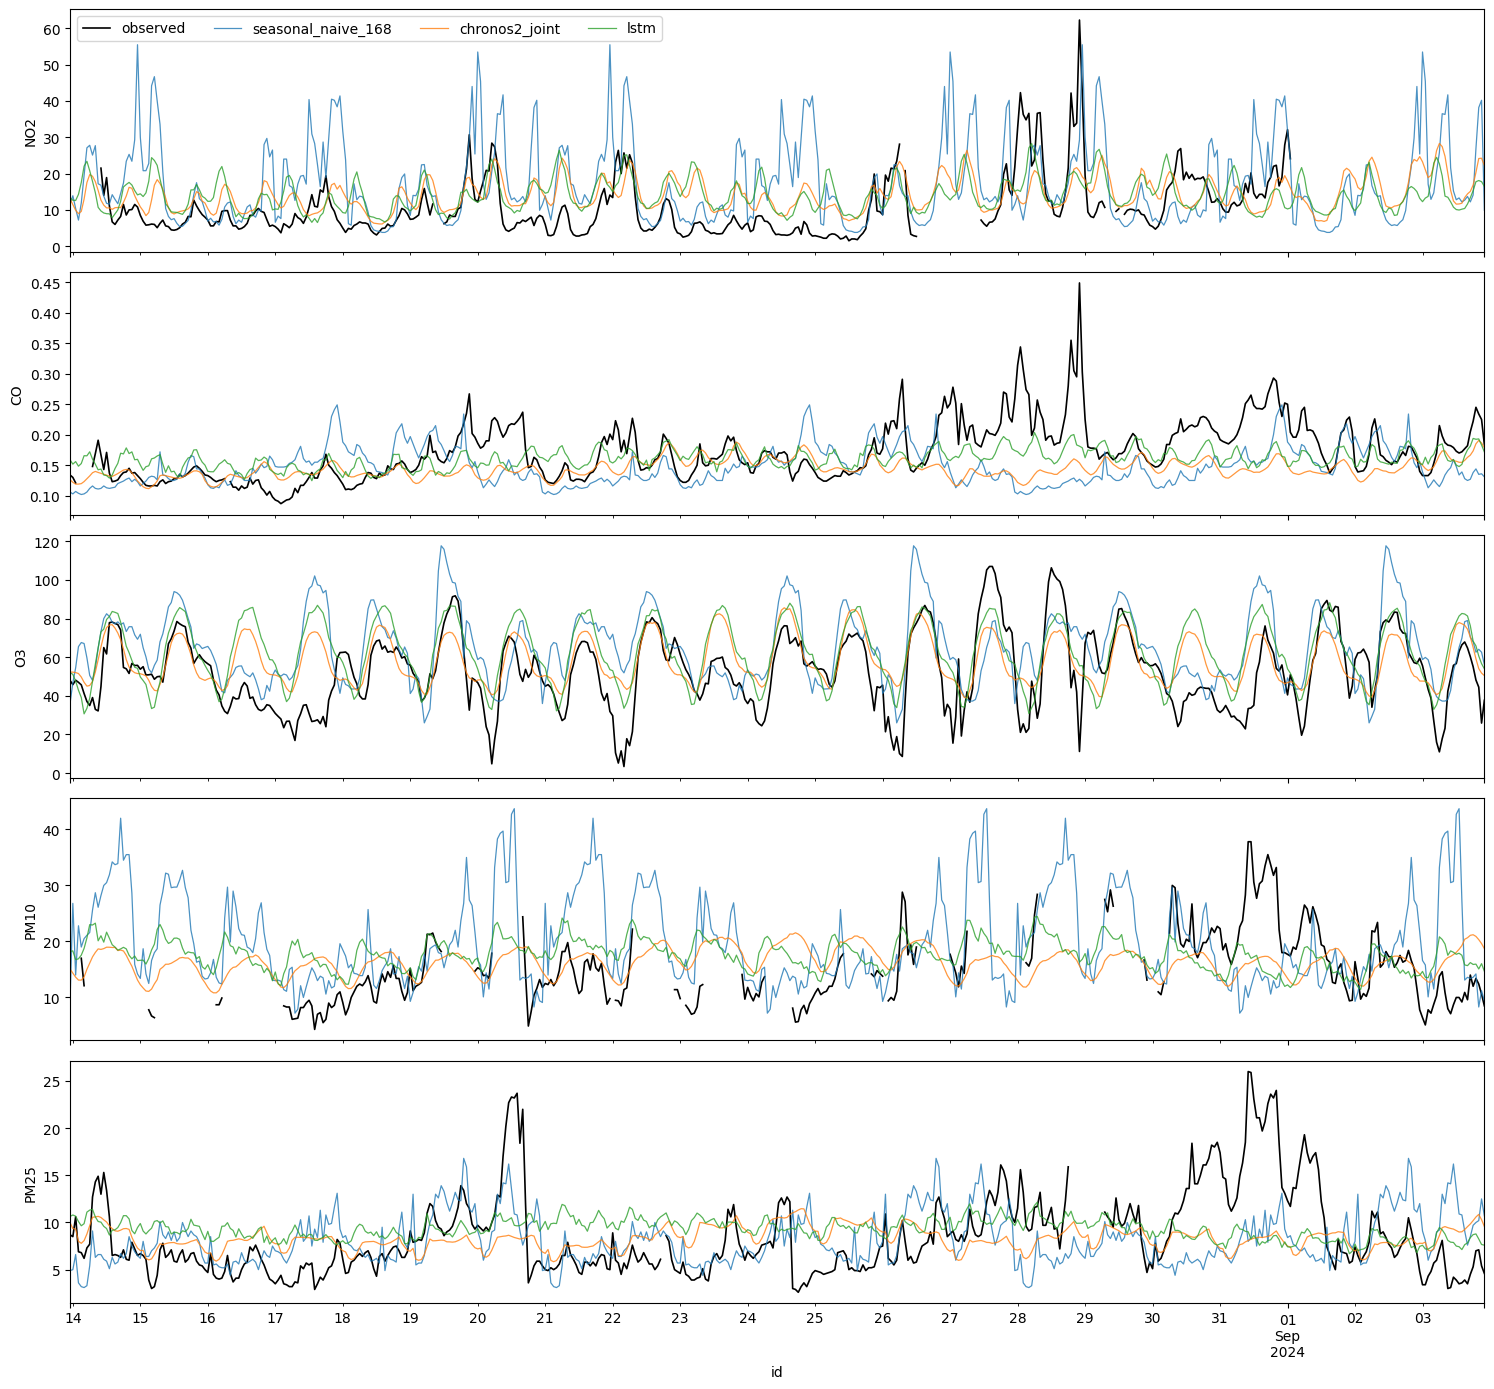

In [32]:
to_plot = ["seasonal_naive_168", "chronos2_joint", "lstm"]
fig, axes = plt.subplots(5, 1, figsize=(15, 14), sharex=True)
for ax, col in zip(axes, POLLUTANTS):
    valid[col].plot(ax=ax, color="black", lw=1.2, label="observed")
    for name in to_plot:
        preds[name][col].plot(ax=ax, lw=0.9, alpha=0.8, label=name)
    ax.set_ylabel(col.replace("valeur_", ""))
axes[0].legend(ncol=4)
plt.tight_layout()

Success: O3. Chronos-2 follows the daily cycle for the whole three weeks.

Failure: the PM25 episode around August 31. Observed values go above 25 and every model stays around 10. The models predict a smooth average day and miss peaks like this one. Seasonal naive has the opposite problem on NO2: it copies peaks from an older week that do not happen again.

## 9. Final forecast

Chronos-2 joint has the lowest average MAE on validation, so I use it for the test period, this time with all of train as context.

In [33]:
final = chronos_joint(train, HORIZON)
assert final.index.equals(test.index)
final.index = test.index  # back to the "id" name

sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
submission = final.clip(lower=0).reset_index()  # a concentration can't be negative
submission["id"] = submission["id"].dt.strftime("%Y-%m-%d %H")
submission.head()

target_name,id,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
0,2024-09-03 23,12.271326,0.167709,41.805740,8.953562,4.923683
1,2024-09-04 00,11.202220,0.158353,41.991302,8.960043,5.056275
2,2024-09-04 01,10.072947,0.153761,40.902069,8.704508,5.359439
3,2024-09-04 02,10.084755,0.151577,39.716370,8.440187,4.754160
4,2024-09-04 03,10.799688,0.152656,37.327644,8.431598,4.604549


In [34]:
# format check against the sample submission
assert list(submission.columns) == list(sample.columns)
assert submission["id"].tolist() == sample["id"].tolist()
assert len(submission) == 504
assert submission.notna().all().all()

OUT_DIR = DATA_DIR.parent.parent / "outputs"
OUT_DIR.mkdir(exist_ok=True)
submission.to_csv(OUT_DIR / "submission.csv", index=False)

if IN_COLAB:
    files.download(str(OUT_DIR / "submission.csv"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The file has the same columns and the same 504 timestamps as the sample submission, in the same order, with no missing value.